# 01 — SmolVLA Baseline Reproduction and G0 Compatibility

## Robustness-Enhanced Vision-Language-Action Learning

**Module:** Deep Learning (`CT100-3-M-DL`)  
**Programme:** Master in Artificial Intelligence  
**Primary policy:** SmolVLA  
**Framework:** Hugging Face LeRobot  
**Primary benchmark:** LIBERO-Spatial  
**Released checkpoint:** `lerobot/smolvla_libero`

---

### Purpose

Notebook 00 established the environment, benchmark and dataset foundation. This notebook moves from **data validation** to the **actual deep-learning policy**.

It has six objectives:

1. Pin and document the exact released SmolVLA LIBERO checkpoint.
2. Decompose the VLA architecture into its learned vision, language, state and action components.
3. Load the policy and its serialized pre/post-processing pipelines on CUDA.
4. Verify one real LIBERO demonstration can produce a finite 7-D model action.
5. Connect the released policy to the official LeRobot LIBERO environment processing path.
6. Complete the **G0 compatibility gate** with a model-generated action and, after the smoke test passes, one complete closed-loop episode.

> **Important:** This notebook does **not** yet claim robustness improvement. It establishes a reproducible released-policy reference and proves the end-to-end VLA inference path before our own fine-tuning experiments.

## G0 compatibility gate

G0 is a technical compatibility gate, not an accuracy benchmark.

G0 passes only when the following chain works:

`WSL/Linux → PyTorch/CUDA → LeRobot → SmolVLA → LIBERO → observation processing → policy inference → 7-D model action → simulator step → complete closed-loop episode`

Task success is desirable, but **not required for G0**. The purpose is to prove that the exact software/hardware stack can execute the policy correctly.

The notebook is intentionally staged. Do not immediately run a long rollout if model loading, preprocessing, or a single model-generated simulator step has not passed.

## 1. Execution policy and experiment configuration

In [1]:
# IMPORTANT:
# Graphics environment variables must be set before importing MuJoCo / LIBERO.

import os

os.environ.setdefault("GALLIUM_DRIVER", "d3d12")
os.environ.setdefault("MESA_D3D12_DEFAULT_ADAPTER_NAME", "NVIDIA")
os.environ.setdefault("MUJOCO_GL", "glfw")

from pathlib import Path
import json
import platform
import subprocess
import sys
import time
from importlib.metadata import PackageNotFoundError, version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

# ------------------------------------------------------------------
# Reproducibility configuration
# ------------------------------------------------------------------
SEED = 42

MODEL_REPO_ID = "lerobot/smolvla_libero"
DATASET_REPO_ID = "lerobot/libero"
LIBERO_SUITE = "libero_spatial"

VIDEO_BACKEND = "pyav"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Technical smoke-test target.
SMOKE_TASK_ID = 0
SMOKE_INIT_STATE_ID = 0

# Do NOT enable the complete rollout until the one-step model-action test passes.
RUN_COMPLETE_CLOSED_LOOP_EPISODE = True

# Optional later timing probe. Keep disabled during first debugging pass.
RUN_TIMING_PROBE = False

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def find_repo_root(start: Path) -> Path:
    current = start.resolve()
    for candidate in [current, *current.parents]:
        if (candidate / ".git").exists():
            return candidate
    # Normal notebook location fallback.
    if current.name == "notebooks":
        return current.parent
    return current

REPO_ROOT = find_repo_root(Path.cwd())

METRICS_DIR = REPO_ROOT / "results" / "metrics" / "baseline_reproduction"
FIGURES_DIR = REPO_ROOT / "results" / "figures" / "baseline_reproduction"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Repository root :", REPO_ROOT)
print("Metrics output  :", METRICS_DIR)
print("Figures output  :", FIGURES_DIR)
print("Device          :", DEVICE)
print("Complete rollout:", RUN_COMPLETE_CLOSED_LOOP_EPISODE)

Repository root : /home/leeming/projects/deep-learning-vla-robustness
Metrics output  : /home/leeming/projects/deep-learning-vla-robustness/results/metrics/baseline_reproduction
Figures output  : /home/leeming/projects/deep-learning-vla-robustness/results/figures/baseline_reproduction
Device          : cuda
Complete rollout: True


## 2. Environment and provenance verification

In [2]:
def package_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "NOT INSTALLED"

environment_rows = [
    ("Python", platform.python_version()),
    ("Platform", platform.platform()),
    ("torch", torch.__version__),
    ("lerobot", package_version("lerobot")),
    ("mujoco", package_version("mujoco")),
    ("hf_libero", package_version("hf_libero")),
    ("transformers", package_version("transformers")),
    ("accelerate", package_version("accelerate")),
    ("torchcodec", package_version("torchcodec")),
    ("av", package_version("av")),
]

environment_df = pd.DataFrame(
    environment_rows,
    columns=["component", "version"],
)

display(environment_df)

print("Python executable:", sys.executable)
print("CUDA available   :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("CUDA runtime     :", torch.version.cuda)
    print("GPU              :", torch.cuda.get_device_name(0))
    print("Compute capability:", torch.cuda.get_device_capability(0))

assert torch.cuda.is_available(), (
    "CUDA is unavailable. Notebook 01 is intended to validate the GPU inference path."
)

,component,version
0,Python,3.12.14
1,Platform,Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-...
2,torch,2.11.0+cu128
3,lerobot,0.6.1
4,mujoco,3.8.1
5,hf_libero,0.1.4
6,transformers,5.5.4
7,accelerate,1.14.0
8,torchcodec,0.11.1
9,av,15.1.0


Python executable: /home/leeming/miniforge3/envs/vla-libero/bin/python
CUDA available   : True
CUDA runtime     : 12.8
GPU              : NVIDIA GeForce RTX 5090
Compute capability: (12, 0)


In [3]:
# Real GPU compute test: this catches kernels that can enumerate CUDA
# but cannot actually execute a CUDA operation.

x = torch.randn(1024, 1024, device=DEVICE)
y = torch.randn(1024, 1024, device=DEVICE)

torch.cuda.synchronize()
t0 = time.perf_counter()

z = x @ y

torch.cuda.synchronize()
elapsed = time.perf_counter() - t0

gpu_compute_summary = {
    "cuda_available": bool(torch.cuda.is_available()),
    "gpu_name": torch.cuda.get_device_name(0),
    "compute_capability": str(torch.cuda.get_device_capability(0)),
    "torch_version": torch.__version__,
    "cuda_runtime": torch.version.cuda,
    "matmul_seconds": float(elapsed),
    "finite_result": bool(torch.isfinite(z).all().item()),
}

display(pd.DataFrame([gpu_compute_summary]))

assert gpu_compute_summary["finite_result"], "CUDA matmul produced non-finite values."

del x, y, z
torch.cuda.empty_cache()

,cuda_available,gpu_name,compute_capability,torch_version,cuda_runtime,matmul_seconds,finite_result
0,True,NVIDIA GeForce RTX 5090,"(12, 0)",2.11.0+cu128,12.8,0.123784,True


In [4]:
def git_sha(path: Path):
    try:
        return subprocess.check_output(
            ["git", "-C", str(path), "rev-parse", "HEAD"],
            text=True,
            stderr=subprocess.DEVNULL,
        ).strip()
    except Exception:
        return None

PROJECT_GIT_SHA = git_sha(REPO_ROOT)
LEROBOT_REPO = Path.home() / "projects" / "lerobot"
LEROBOT_GIT_SHA = git_sha(LEROBOT_REPO)

provenance_df = pd.DataFrame([
    {"repository": "project", "path": str(REPO_ROOT), "git_sha": PROJECT_GIT_SHA},
    {"repository": "lerobot", "path": str(LEROBOT_REPO), "git_sha": LEROBOT_GIT_SHA},
])

display(provenance_df)

,repository,path,git_sha
0,project,/home/leeming/projects/deep-learning-vla-robus...,153a3b639fadc6f19bd77edb3e4a44cfe2aab3fb
1,lerobot,/home/leeming/projects/lerobot,7e241bd630a3719a56157a497ce5d08f244784f1


## 3. Pin the released SmolVLA LIBERO checkpoint

In [5]:
from huggingface_hub import HfApi

hf_api = HfApi()
model_info = hf_api.model_info(MODEL_REPO_ID)

MODEL_REVISION = model_info.sha

print("Model repo      :", MODEL_REPO_ID)
print("Resolved revision:", MODEL_REVISION)

assert MODEL_REVISION, "Could not resolve a concrete SmolVLA checkpoint revision."

/home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model repo      : lerobot/smolvla_libero
Resolved revision: 31d453f7edd78c839a8bbc39744a292686daf0de


In [6]:
# Download the exact pinned snapshot rather than relying on a moving `main`.
# First execution may download ~1 GB of model files.

from huggingface_hub import snapshot_download

MODEL_SNAPSHOT_DIR = Path(
    snapshot_download(
        repo_id=MODEL_REPO_ID,
        revision=MODEL_REVISION,
    )
)

print("Pinned model snapshot:")
print(MODEL_SNAPSHOT_DIR)

required_model_files = [
    "config.json",
    "model.safetensors",
    "policy_preprocessor.json",
    "policy_postprocessor.json",
]

checkpoint_file_rows = []

for filename in required_model_files:
    path = MODEL_SNAPSHOT_DIR / filename
    checkpoint_file_rows.append({
        "file": filename,
        "exists": path.exists(),
        "size_mb": round(path.stat().st_size / (1024**2), 3) if path.exists() else None,
    })

checkpoint_files_df = pd.DataFrame(checkpoint_file_rows)
display(checkpoint_files_df)

assert checkpoint_files_df["exists"].all(), (
    "The pinned checkpoint snapshot is missing one or more required files."
)

Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 1591.16it/s]

Pinned model snapshot:
/home/leeming/.cache/huggingface/hub/models--lerobot--smolvla_libero/snapshots/31d453f7edd78c839a8bbc39744a292686daf0de


,file,exists,size_mb
0,config.json,True,0.002
1,model.safetensors,True,864.708
2,policy_preprocessor.json,True,0.002
3,policy_postprocessor.json,True,0.001


## 4. SmolVLA architecture decomposition

This section makes the **Deep Learning** content explicit.

SmolVLA is not simply a conventional single-input predictor. It is a multimodal neural policy that combines:

- visual observations from multiple cameras,
- a natural-language task instruction,
- robot proprioceptive state,
- a learned vision-language backbone,
- state/action projection layers,
- and a learned flow-matching action expert that generates continuous robot actions.

The exact checkpoint configuration is inspected below rather than hard-coded from documentation.

In [7]:
with open(MODEL_SNAPSHOT_DIR / "config.json", "r") as f:
    model_config_json = json.load(f)

with open(MODEL_SNAPSHOT_DIR / "policy_preprocessor.json", "r") as f:
    preprocessor_config_json = json.load(f)

with open(MODEL_SNAPSHOT_DIR / "policy_postprocessor.json", "r") as f:
    postprocessor_config_json = json.load(f)

selected_config_fields = [
    "type",
    "n_obs_steps",
    "chunk_size",
    "n_action_steps",
    "max_state_dim",
    "max_action_dim",
    "resize_imgs_with_padding",
    "tokenizer_max_length",
    "num_steps",
    "vlm_model_name",
    "attention_mode",
    "num_vlm_layers",
    "num_expert_layers",
    "expert_width_multiplier",
    "freeze_vision_encoder",
    "train_expert_only",
    "train_state_proj",
]

config_rows = [
    {"field": key, "value": model_config_json.get(key)}
    for key in selected_config_fields
]

display(pd.DataFrame(config_rows))

,field,value
0,type,smolvla
1,n_obs_steps,1
2,chunk_size,50
3,n_action_steps,50
4,max_state_dim,32
5,max_action_dim,32
6,resize_imgs_with_padding,"[512, 512]"
7,tokenizer_max_length,48
8,num_steps,10
9,vlm_model_name,HuggingFaceTB/SmolVLM2-500M-Video-Instruct


In [8]:
def feature_table(feature_dict):
    rows = []
    for name, spec in feature_dict.items():
        rows.append({
            "feature": name,
            "type": spec.get("type"),
            "shape": spec.get("shape"),
        })
    return pd.DataFrame(rows)

print("Checkpoint input features")
display(feature_table(model_config_json.get("input_features", {})))

print("Checkpoint output features")
display(feature_table(model_config_json.get("output_features", {})))

architecture_rows = [
    {
        "component": "Vision-language backbone",
        "checkpoint_setting": model_config_json.get("vlm_model_name"),
        "role": "Jointly encodes visual observations and language instruction",
    },
    {
        "component": "Vision encoder",
        "checkpoint_setting": "inside SmolVLM2",
        "role": "Transforms camera images into learned visual embeddings",
    },
    {
        "component": "Language model",
        "checkpoint_setting": "inside SmolVLM2",
        "role": "Transforms tokenized task instruction into contextual embeddings",
    },
    {
        "component": "Robot-state projection",
        "checkpoint_setting": f"max_state_dim={model_config_json.get('max_state_dim')}",
        "role": "Projects proprioceptive state into model hidden representation",
    },
    {
        "component": "Action expert",
        "checkpoint_setting": f"chunk_size={model_config_json.get('chunk_size')}",
        "role": "Generates continuous robot action chunks conditioned on multimodal context",
    },
    {
        "component": "Flow-matching inference",
        "checkpoint_setting": f"num_steps={model_config_json.get('num_steps')}",
        "role": "Iteratively maps noise to robot actions",
    },
]

display(pd.DataFrame(architecture_rows))

Checkpoint input features


,feature,type,shape
0,observation.state,STATE,[6]
1,observation.images.camera1,VISUAL,"[3, 256, 256]"
2,observation.images.camera2,VISUAL,"[3, 256, 256]"
3,observation.images.camera3,VISUAL,"[3, 256, 256]"


Checkpoint output features


,feature,type,shape
0,action,ACTION,[7]


,component,checkpoint_setting,role
0,Vision-language backbone,HuggingFaceTB/SmolVLM2-500M-Video-Instruct,Jointly encodes visual observations and langua...
1,Vision encoder,inside SmolVLM2,Transforms camera images into learned visual e...
2,Language model,inside SmolVLM2,Transforms tokenized task instruction into con...
3,Robot-state projection,max_state_dim=32,Projects proprioceptive state into model hidde...
4,Action expert,chunk_size=50,Generates continuous robot action chunks condi...
5,Flow-matching inference,num_steps=10,Iteratively maps noise to robot actions


In [9]:
# Inspect serialized preprocessing stages because normalization and feature renaming
# are part of the released model definition and must remain reproducible.

processor_rows = []

for i, step in enumerate(preprocessor_config_json.get("steps", [])):
    processor_rows.append({
        "order": i,
        "registry_name": step.get("registry_name"),
        "config": json.dumps(step.get("config", {}), sort_keys=True)[:500],
    })

display(pd.DataFrame(processor_rows))

,order,registry_name,config
0,0,rename_observations_processor,"{""rename_map"": {""observation.images.image"": ""o..."
1,1,to_batch_processor,{}
2,2,smolvla_new_line_processor,{}
3,3,tokenizer_processor,"{""max_length"": 48, ""padding"": ""max_length"", ""p..."
4,4,device_processor,"{""device"": ""cuda"", ""float_dtype"": null}"
5,5,normalizer_processor,"{""eps"": 1e-08, ""features"": {""action"": {""shape""..."


### Compatibility note

Notebook 00 observed the LIBERO-Spatial demonstration dataset empirically. The checkpoint may encode its own state/image feature contract.

We therefore **compare** the checkpoint feature contract against the real dataset instead of silently assuming they are identical. If a mismatch is discovered, it becomes a reproducibility finding that must be resolved before G0 can pass.

## 5. Load the policy and serialized policy processors

In [10]:
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy
from lerobot.policies.factory import make_pre_post_processors

torch.cuda.empty_cache()

load_start = time.perf_counter()

policy = SmolVLAPolicy.from_pretrained(
    str(MODEL_SNAPSHOT_DIR)
)

policy = policy.to(DEVICE)
policy.eval()
policy.reset()

if torch.cuda.is_available():
    torch.cuda.synchronize()

MODEL_LOAD_SECONDS = time.perf_counter() - load_start

preprocessor, postprocessor = make_pre_post_processors(
    policy_cfg=policy.config,
    pretrained_path=str(MODEL_SNAPSHOT_DIR),
    preprocessor_overrides={
        "device_processor": {
            "device": DEVICE,
        }
    },
)

print("Policy class     :", type(policy).__name__)
print("Policy device    :", next(policy.parameters()).device)
print("Model load time  :", round(MODEL_LOAD_SECONDS, 3), "s")
print("Preprocessor     :", type(preprocessor).__name__)
print("Postprocessor    :", type(postprocessor).__name__)

Loading  HuggingFaceTB/SmolVLM2-500M-Video-Instruct weights ...


`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 489/489 [00:00<00:00, 898.55it/s]


Reducing the number of VLM layers to 16 ...
Loading weights from local directory
Policy class     : SmolVLAPolicy
Policy device    : cuda:0
Model load time  : 11.829 s
Preprocessor     : DataProcessorPipeline
Postprocessor    : DataProcessorPipeline


In [11]:
total_params = sum(p.numel() for p in policy.parameters())
trainable_params = sum(
    p.numel() for p in policy.parameters()
    if p.requires_grad
)

model_parameter_summary = {
    "total_parameters": int(total_params),
    "trainable_parameters_current_config": int(trainable_params),
    "parameter_size_millions": float(total_params / 1e6),
    "model_load_seconds": float(MODEL_LOAD_SECONDS),
    "cuda_allocated_mb": float(torch.cuda.memory_allocated() / (1024**2)),
    "cuda_reserved_mb": float(torch.cuda.memory_reserved() / (1024**2)),
}

display(
    pd.DataFrame([model_parameter_summary]).T.rename(
        columns={0: "Value"}
    )
)

with open(METRICS_DIR / "smolvla_model_parameter_summary.json", "w") as f:
    json.dump(model_parameter_summary, f, indent=2)

,Value
total_parameters,4.500462e+08
trainable_parameters_current_config,3.929041e+08
parameter_size_millions,4.500462e+02
model_load_seconds,1.182871e+01
cuda_allocated_mb,8.926235e+02
cuda_reserved_mb,9.060000e+02


## 6. Offline inference on a real LIBERO-Spatial demonstration

In [12]:
# Reuse the exact dataset revision recorded by Notebook 00 when available.

NOTEBOOK00_SUMMARY = (
    REPO_ROOT
    / "results"
    / "metrics"
    / "dataset_eda"
    / "dataset_eda_summary.json"
)

if NOTEBOOK00_SUMMARY.exists():
    with open(NOTEBOOK00_SUMMARY, "r") as f:
        notebook00_summary = json.load(f)

    DATASET_REVISION = notebook00_summary["dataset_revision"]

    print("Loaded dataset revision from Notebook 00:")
    print(DATASET_REVISION)
else:
    dataset_info = hf_api.dataset_info(DATASET_REPO_ID)
    DATASET_REVISION = dataset_info.sha

    print("Notebook 00 summary not found.")
    print("Resolved current dataset revision instead:")
    print(DATASET_REVISION)

assert DATASET_REVISION

Loaded dataset revision from Notebook 00:
a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4


In [13]:
# Select one episode from the candidate validation split when available.
# This is only an inference compatibility sample; it is NOT being used as the
# final closed-loop test.

candidate_split_path = (
    REPO_ROOT
    / "configs"
    / "splits"
    / f"libero_spatial_split_candidate_seed{SEED}.csv"
)

if candidate_split_path.exists():
    split_df = pd.read_csv(candidate_split_path)

    validation_rows = split_df[
        split_df["split"].astype(str).str.lower().isin(
            ["validation", "val"]
        )
    ]

    if len(validation_rows) == 0:
        raise RuntimeError(
            "Candidate split exists but no validation rows were found."
        )

    OFFLINE_EPISODE_ID = int(
        validation_rows.iloc[0]["episode_index"]
    )
else:
    # Fallback only if the split was not copied into the repository.
    OFFLINE_EPISODE_ID = 0

print("Offline compatibility episode:", OFFLINE_EPISODE_ID)

Offline compatibility episode: 1292


In [14]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset

offline_dataset = LeRobotDataset(
    DATASET_REPO_ID,
    revision=DATASET_REVISION,
    episodes=[OFFLINE_EPISODE_ID],
    video_backend=VIDEO_BACKEND,
)

print("Episode frames:", offline_dataset.num_frames)
print("Camera keys   :", offline_dataset.meta.camera_keys)

offline_sample_position = offline_dataset.num_frames // 2
offline_sample = offline_dataset[offline_sample_position]

print("\nRaw sample keys:")
for key in sorted(offline_sample.keys()):
    value = offline_sample[key]
    if isinstance(value, torch.Tensor):
        print(
            f"{key:45s}",
            tuple(value.shape),
            value.dtype,
        )
    else:
        print(
            f"{key:45s}",
            type(value).__name__,
        )

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1149.20it/s]


Episode frames: 157
Camera keys   : ['observation.images.image', 'observation.images.image2']

Raw sample keys:
action                                        (7,) torch.float32
episode_index                                 () torch.int64
frame_index                                   () torch.int64
index                                         () torch.int64
observation.images.image                      (3, 256, 256) torch.float32
observation.images.image2                     (3, 256, 256) torch.float32
observation.state                             (8,) torch.float32
task                                          str
task_index                                    () torch.int64
timestamp                                     () torch.float32


In [15]:
# Guarantee a language task string is present for the tokenizer.
# Some LeRobot dataset-reader versions already expose "task"; this fallback
# reconstructs it from task_index and metadata.

def scalar_int(value):
    if isinstance(value, torch.Tensor):
        return int(value.detach().cpu().reshape(-1)[0].item())
    return int(value)

if "task" not in offline_sample:
    task_idx = scalar_int(
        offline_sample["task_index"]
    )

    tasks_df = offline_dataset.meta.tasks

    matching_task_text = [
        str(task_text)
        for task_text, row in tasks_df.iterrows()
        if int(row["task_index"]) == task_idx
    ]

    if len(matching_task_text) != 1:
        raise RuntimeError(
            f"Could not uniquely recover language instruction for task_index={task_idx}."
        )

    offline_sample["task"] = matching_task_text[0]

print("Language instruction:")
print(offline_sample["task"])

Language instruction:
pick up the black bowl next to the cookie box and place it on the plate


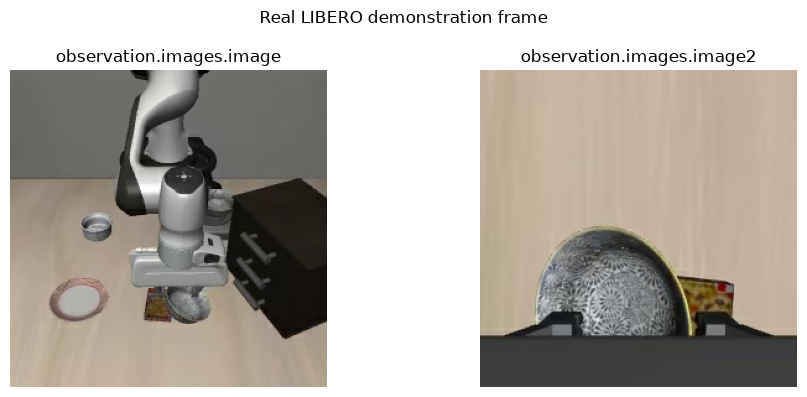

In [16]:
# Visualize the real demonstration frame.
# Dataset frames are shown as stored; no manual simulator flip is applied here.

camera_keys = list(offline_dataset.meta.camera_keys)

fig, axes = plt.subplots(
    1,
    len(camera_keys),
    figsize=(5 * len(camera_keys), 4),
)

if len(camera_keys) == 1:
    axes = [axes]

for ax, camera_key in zip(axes, camera_keys):
    image = offline_sample[camera_key]

    if isinstance(image, torch.Tensor):
        image = image.detach().cpu()

        if image.ndim == 3 and image.shape[0] in (1, 3, 4):
            image = image.permute(1, 2, 0)

        image = image.numpy()

    ax.imshow(image)
    ax.set_title(camera_key)
    ax.axis("off")

fig.suptitle("Real LIBERO demonstration frame")
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "offline_demonstration_frame.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

### Checkpoint ↔ dataset feature compatibility

This is an important research checkpoint.

The offline dataset sample is passed through the **serialized checkpoint preprocessor**. We inspect the result before asking the VLA to generate an action. This catches feature-name, state-dimension, normalization and tokenizer incompatibilities early.

In [17]:
# Use a shallow copy because the processor may transform values.
raw_offline_batch = dict(offline_sample)

preprocessed_offline_batch = preprocessor(
    raw_offline_batch
)

print("Preprocessed keys:")

for key in sorted(preprocessed_offline_batch.keys()):
    value = preprocessed_offline_batch[key]

    if isinstance(value, torch.Tensor):
        print(
            f"{key:55s}",
            tuple(value.shape),
            value.dtype,
            value.device,
        )
    else:
        print(
            f"{key:55s}",
            type(value).__name__,
        )

Preprocessed keys:
action                                                  (1, 7) torch.float32 cuda:0
episode_index                                           () torch.int64 cuda:0
index                                                   (1,) torch.int64 cuda:0
info                                                    dict
next.done                                               bool
next.reward                                             float
next.truncated                                          bool
observation.images.camera1                              (1, 3, 256, 256) torch.float32 cuda:0
observation.images.camera2                              (1, 3, 256, 256) torch.float32 cuda:0
observation.language.attention_mask                     (1, 48) torch.bool cuda:0
observation.language.tokens                             (1, 48) torch.int64 cuda:0
observation.state                                       (1, 8) torch.float32 cuda:0
task                                                    l

In [18]:
# Generate one real model action from a demonstration observation.

policy.reset()

if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

inference_start = time.perf_counter()

with torch.inference_mode():
    offline_action_normalized = policy.select_action(
        preprocessed_offline_batch
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

offline_inference_seconds = (
    time.perf_counter() - inference_start
)

offline_action = postprocessor(
    offline_action_normalized
)

if isinstance(offline_action, torch.Tensor):
    offline_action_tensor = offline_action.detach().cpu()
else:
    offline_action_tensor = torch.as_tensor(
        offline_action
    )

offline_action_flat = offline_action_tensor.reshape(-1)

offline_action_summary = {
    "shape": str(tuple(offline_action_tensor.shape)),
    "action_dim": int(offline_action_flat.numel()),
    "finite": bool(
        torch.isfinite(
            offline_action_tensor
        ).all().item()
    ),
    "min": float(offline_action_flat.min().item()),
    "max": float(offline_action_flat.max().item()),
    "inference_seconds_first_action": float(
        offline_inference_seconds
    ),
    "cuda_peak_memory_mb": float(
        torch.cuda.max_memory_allocated()
        / (1024**2)
    ),
}

display(
    pd.DataFrame([offline_action_summary]).T.rename(
        columns={0: "Value"}
    )
)

print("\nPostprocessed 7-D action:")
print(offline_action_tensor)

assert offline_action_summary["finite"], (
    "Model produced non-finite action values."
)

assert offline_action_summary["action_dim"] == 7, (
    "Expected a 7-D LIBERO action after postprocessing."
)

,Value
shape,"(1, 7)"
action_dim,7
finite,True
min,-1.010436
max,0.005374
inference_seconds_first_action,0.728918
cuda_peak_memory_mb,925.521973



Postprocessed 7-D action:
tensor([[-0.0649, -0.2244, -0.9717,  0.0054, -0.0419, -0.0588, -1.0104]])


## 7. Official LeRobot LIBERO environment processing path

For closed-loop inference we should **not manually reproduce** all simulator-to-model transformations.

The official LeRobot evaluation path separates:

1. raw Gym/LIBERO observation,
2. generic observation tensor conversion,
3. environment-specific LIBERO preprocessing,
4. policy-specific SmolVLA preprocessing,
5. policy inference,
6. policy action postprocessing,
7. environment action postprocessing,
8. simulator step.

This is particularly important for LIBERO camera orientation and proprioceptive-state conversion.

In [19]:
# Import the official LeRobot evaluation building blocks.
# The fallback imports make the notebook tolerant to small packaging differences
# while still failing clearly if the installed LeRobot build lacks the required API.

from lerobot.envs.configs import LiberoEnv as LiberoEnvConfig

try:
    from lerobot.envs.factory import (
        make_env,
        make_env_pre_post_processors,
    )
except ImportError:
    from lerobot.envs import (
        make_env,
        make_env_pre_post_processors,
    )

from lerobot.envs.utils import preprocess_observation
from lerobot.utils.constants import ACTION

env_cfg = LiberoEnvConfig(
    task=LIBERO_SUITE,
    task_ids=[SMOKE_TASK_ID],
    obs_type="pixels_agent_pos",
    camera_name=(
        "agentview_image,"
        "robot0_eye_in_hand_image"
    ),
    init_states=True,
    observation_height=256,
    observation_width=256,
    control_mode="relative",
)

env_preprocessor, env_postprocessor = (
    make_env_pre_post_processors(
        env_cfg=env_cfg,
        policy_cfg=policy.config,
    )
)

print(env_cfg)
print("Environment preprocessor :", type(env_preprocessor).__name__)
print("Environment postprocessor:", type(env_postprocessor).__name__)

LiberoEnv(task='libero_spatial', fps=20, features={'action': PolicyFeature(type=<FeatureType.ACTION: 'ACTION'>, shape=(7,)), 'pixels/agentview_image': PolicyFeature(type=<FeatureType.VISUAL: 'VISUAL'>, shape=(256, 256, 3)), 'pixels/robot0_eye_in_hand_image': PolicyFeature(type=<FeatureType.VISUAL: 'VISUAL'>, shape=(256, 256, 3)), 'robot_state/eef/pos': PolicyFeature(type=<FeatureType.STATE: 'STATE'>, shape=(3,)), 'robot_state/eef/quat': PolicyFeature(type=<FeatureType.STATE: 'STATE'>, shape=(4,)), 'robot_state/eef/mat': PolicyFeature(type=<FeatureType.STATE: 'STATE'>, shape=(3, 3)), 'robot_state/gripper/qpos': PolicyFeature(type=<FeatureType.STATE: 'STATE'>, shape=(2,)), 'robot_state/gripper/qvel': PolicyFeature(type=<FeatureType.STATE: 'STATE'>, shape=(2,)), 'robot_state/joints/pos': PolicyFeature(type=<FeatureType.STATE: 'STATE'>, shape=(7,)), 'robot_state/joints/vel': PolicyFeature(type=<FeatureType.STATE: 'STATE'>, shape=(7,))}, features_map={'action': 'action', 'robot_state/eef/po

In [20]:
# Build one synchronous vector environment for task 0 only.
# This is intentionally small for compatibility debugging.

envs = make_env(
    env_cfg,
    n_envs=1,
    use_async_envs=False,
)

print("Suites returned:", list(envs.keys()))

suite_envs = envs[LIBERO_SUITE]
print("Task IDs returned:", list(suite_envs.keys()))

smoke_env = suite_envs[SMOKE_TASK_ID]

print("Vector env type:", type(smoke_env).__name__)
print("Number of envs  :", smoke_env.num_envs)

[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /home/leeming/miniforge3/envs/vla-libero/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)


Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1
Suites returned: ['libero_spatial']
Task IDs returned: [0]
Vector env type: SyncVectorEnv
Number of envs  : 1


## 8. One model-generated simulator step

In [21]:
# Reset one LIBERO environment and build the exact observation path used by
# LeRobot evaluation.

policy.reset()

raw_observation, reset_info = smoke_env.reset(
    seed=SEED
)

observation = preprocess_observation(
    raw_observation
)

# Add the natural-language task description expected by SmolVLA.
try:
    observation["task"] = list(
        smoke_env.call(
            "task_description"
        )
    )
except Exception:
    observation["task"] = [
        str(
            smoke_env.call("task")[0]
        )
    ]

print("Task instruction:")
print(observation["task"])

print("\nAfter generic preprocess_observation:")
for key in sorted(observation.keys()):
    value = observation[key]
    if isinstance(value, torch.Tensor):
        print(key, tuple(value.shape), value.dtype)
    else:
        print(key, type(value).__name__)

Local assets not found. Downloading from HuggingFace Hub...
Assets already downloaded at /home/leeming/.cache/libero/assets
Task instruction:
['pick up the black bowl between the plate and the ramekin and place it on the plate']

After generic preprocess_observation:
observation.images.image (1, 3, 256, 256) torch.float32
observation.images.image2 (1, 3, 256, 256) torch.float32
observation.robot_state dict
task list


In [22]:
# Apply the official LIBERO environment processor.
# This stage handles LIBERO-specific representation conventions.

env_processed_observation = env_preprocessor(
    observation
)

print("After LIBERO environment preprocessor:")
for key in sorted(env_processed_observation.keys()):
    value = env_processed_observation[key]

    if isinstance(value, torch.Tensor):
        print(
            key,
            tuple(value.shape),
            value.dtype,
        )
    else:
        print(
            key,
            type(value).__name__,
        )

After LIBERO environment preprocessor:
action NoneType
info dict
next.done bool
next.reward float
next.truncated bool
observation.images.image (1, 3, 256, 256) torch.float32
observation.images.image2 (1, 3, 256, 256) torch.float32
observation.state (1, 8) torch.float32
task list


In [23]:
# Apply the released SmolVLA checkpoint preprocessor.

policy_input = preprocessor(
    env_processed_observation
)

print("Final SmolVLA input:")
for key in sorted(policy_input.keys()):
    value = policy_input[key]

    if isinstance(value, torch.Tensor):
        print(
            key,
            tuple(value.shape),
            value.dtype,
            value.device,
        )
    else:
        print(
            key,
            type(value).__name__,
        )

Final SmolVLA input:
action NoneType
info dict
next.done bool
next.reward float
next.truncated bool
observation.images.camera1 (1, 3, 256, 256) torch.float32 cuda:0
observation.images.camera2 (1, 3, 256, 256) torch.float32 cuda:0
observation.language.attention_mask (1, 48) torch.bool cuda:0
observation.language.tokens (1, 48) torch.int64 cuda:0
observation.state (1, 8) torch.float32 cuda:0
task list


In [24]:
# Generate one policy action and execute it in LIBERO.

policy.reset()

if torch.cuda.is_available():
    torch.cuda.synchronize()

t0 = time.perf_counter()

with torch.inference_mode():
    action_normalized = policy.select_action(
        policy_input
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

policy_latency_seconds = time.perf_counter() - t0

action = postprocessor(
    action_normalized
)

action_transition = {
    ACTION: action,
}

action_transition = env_postprocessor(
    action_transition
)

action_for_env = action_transition[ACTION]

if isinstance(action_for_env, torch.Tensor):
    action_for_env = (
        action_for_env
        .detach()
        .cpu()
        .numpy()
    )

action_for_env = np.asarray(
    action_for_env,
    dtype=np.float32,
)

print("Action shape :", action_for_env.shape)
print("Action       :", action_for_env)
print("Finite       :", np.isfinite(action_for_env).all())
print("Policy latency:", round(policy_latency_seconds, 4), "s")

assert action_for_env.shape == (1, 7), (
    f"Expected vector-env action shape (1, 7), got {action_for_env.shape}."
)

assert np.isfinite(action_for_env).all(), (
    "Model-generated simulator action contains non-finite values."
)

next_observation, reward, terminated, truncated, step_info = (
    smoke_env.step(
        action_for_env
    )
)

single_step_summary = {
    "task_id": SMOKE_TASK_ID,
    "action_shape": str(action_for_env.shape),
    "finite_action": bool(np.isfinite(action_for_env).all()),
    "reward": float(np.asarray(reward).reshape(-1)[0]),
    "terminated": bool(np.asarray(terminated).reshape(-1)[0]),
    "truncated": bool(np.asarray(truncated).reshape(-1)[0]),
    "policy_latency_seconds": float(policy_latency_seconds),
    "model_generated_simulator_step": "PASS",
}

display(pd.DataFrame([single_step_summary]))

with open(
    METRICS_DIR / "g0_single_model_step.json",
    "w",
) as f:
    json.dump(
        single_step_summary,
        f,
        indent=2,
    )

Action shape : (1, 7)
Action       : [[ 8.5734293e-02  2.1606773e-02  6.8810709e-02 -6.3509046e-04
   6.9189491e-04 -6.9325110e-03 -9.9870592e-01]]
Finite       : True
Policy latency: 0.1222 s


,task_id,action_shape,finite_action,reward,terminated,truncated,policy_latency_seconds,model_generated_simulator_step
0,0,"(1, 7)",True,0.0,False,False,0.12216,PASS


## 9. Complete closed-loop episode — final G0 step

Only enable this after Section 8 passes.

Set near the top of the notebook:

```python
RUN_COMPLETE_CLOSED_LOOP_EPISODE = True
```

Then rerun from the environment-creation section onward.

For LIBERO-Spatial, LeRobot's current environment wrapper allows up to 280 simulator steps by default. The rollout below stops on environment termination/truncation or that maximum horizon. **G0 does not require task success**, only a technically valid complete closed-loop episode.

In [30]:
def extract_success(info, reward_value):
    # LIBERO reward is typically positive on task success.
    success = bool(reward_value > 0)

    if isinstance(info, dict):
        for key in ("is_success", "success"):
            if key in info:
                try:
                    success = success or bool(
                        np.asarray(
                            info[key]
                        ).reshape(-1)[0]
                    )
                except Exception:
                    pass

    return success


closed_loop_summary = None
closed_loop_trace_df = None

if not RUN_COMPLETE_CLOSED_LOOP_EPISODE:
    print(
        "Complete closed-loop rollout is DISABLED.\n"
        "After the single model-generated simulator step passes, "
        "set RUN_COMPLETE_CLOSED_LOOP_EPISODE = True and rerun this section."
    )
else:
    # Recreate the environment after the single-step smoke test so that
    # G0 starts from a clean deterministic reset.
    try:
        smoke_env.close()
    except Exception:
        pass

    envs = make_env(
        env_cfg,
        n_envs=1,
        use_async_envs=False,
    )

    smoke_env = envs[LIBERO_SUITE][SMOKE_TASK_ID]

    policy.reset()

    raw_obs, reset_info = smoke_env.reset(
        seed=SEED
    )

    max_steps = int(
        smoke_env.call(
            "_max_episode_steps"
        )[0]
    )

    rollout_rows = []
    success = False

    rollout_start = time.perf_counter()

    for step_index in range(max_steps):

        obs = preprocess_observation(
            raw_obs
        )

        try:
            obs["task"] = list(
                smoke_env.call(
                    "task_description"
                )
            )
        except Exception:
            obs["task"] = [
                str(
                    smoke_env.call("task")[0]
                )
            ]

        obs = env_preprocessor(obs)
        obs = preprocessor(obs)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        infer_start = time.perf_counter()

        with torch.inference_mode():
            act = policy.select_action(obs)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        infer_seconds = (
            time.perf_counter()
            - infer_start
        )

        act = postprocessor(act)
        act_transition = {ACTION: act}
        act_transition = env_postprocessor(
            act_transition
        )

        act_env = act_transition[ACTION]

        if isinstance(act_env, torch.Tensor):
            act_env = (
                act_env
                .detach()
                .cpu()
                .numpy()
            )

        act_env = np.asarray(
            act_env,
            dtype=np.float32,
        )

        if not np.isfinite(act_env).all():
            raise RuntimeError(
                f"Non-finite action at step {step_index}."
            )

        raw_obs, reward, terminated, truncated, info = (
            smoke_env.step(
                act_env
            )
        )

        reward_value = float(
            np.asarray(
                reward
            ).reshape(-1)[0]
        )

        terminated_value = bool(
            np.asarray(
                terminated
            ).reshape(-1)[0]
        )

        truncated_value = bool(
            np.asarray(
                truncated
            ).reshape(-1)[0]
        )

        success = success or extract_success(
            info,
            reward_value,
        )

        rollout_rows.append({
            "step": step_index,
            "reward": reward_value,
            "terminated": terminated_value,
            "truncated": truncated_value,
            "inference_seconds": float(infer_seconds),
            "action_l2": float(
                np.linalg.norm(
                    act_env.reshape(-1)
                )
            ),
            "success_so_far": bool(success),
        })

        if terminated_value or truncated_value or success:
            break

    rollout_seconds = (
        time.perf_counter()
        - rollout_start
    )

    closed_loop_trace_df = pd.DataFrame(
        rollout_rows
    )

    closed_loop_summary = {
        "task_id": SMOKE_TASK_ID,
        "seed": SEED,
        "steps_executed": int(
            len(closed_loop_trace_df)
        ),
        "max_steps": int(max_steps),
        "success": bool(success),
        "episode_completed": True,
        "wall_seconds": float(
            rollout_seconds
        ),
        "mean_select_action_seconds": float(
            closed_loop_trace_df[
                "inference_seconds"
            ].mean()
        ),
        "median_select_action_seconds": float(
            closed_loop_trace_df[
                "inference_seconds"
            ].median()
        ),
        "max_select_action_seconds": float(
            closed_loop_trace_df[
                "inference_seconds"
            ].max()
        ),
    }

    display(
        pd.DataFrame(
            [closed_loop_summary]
        )
    )

    closed_loop_trace_df.to_csv(
        METRICS_DIR
        / "g0_closed_loop_trace_task0.csv",
        index=False,
    )

    with open(
        METRICS_DIR
        / "g0_closed_loop_summary_task0.json",
        "w",
    ) as f:
        json.dump(
            closed_loop_summary,
            f,
            indent=2,
        )

Creating LIBERO envs | suites=['libero_spatial'] | n_envs(per task)=1 | init_states=True
Restricting to task_ids=[0]
[info] using task orders [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Built vec env | suite=libero_spatial | task_id=0 | n_envs=1


,task_id,seed,steps_executed,max_steps,success,episode_completed,wall_seconds,mean_select_action_seconds,median_select_action_seconds,max_select_action_seconds
0,0,42,80,280,True,True,5.305292,0.004771,0.001108,0.164534


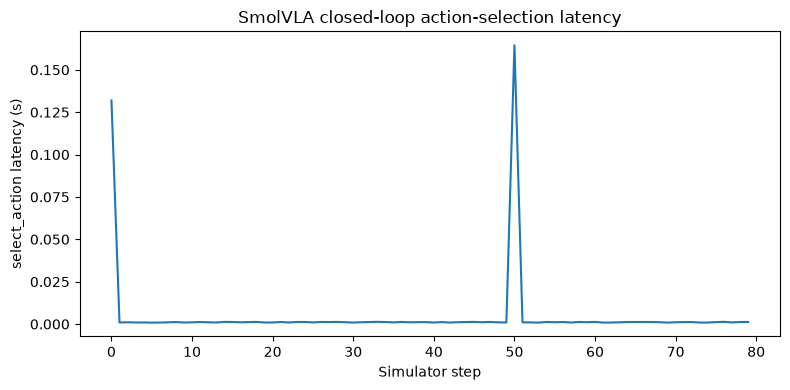

In [31]:
if (
    RUN_COMPLETE_CLOSED_LOOP_EPISODE
    and closed_loop_trace_df is not None
):
    fig, ax = plt.subplots(
        figsize=(8, 4)
    )

    ax.plot(
        closed_loop_trace_df["step"],
        closed_loop_trace_df[
            "inference_seconds"
        ],
    )

    ax.set_xlabel("Simulator step")
    ax.set_ylabel(
        "select_action latency (s)"
    )
    ax.set_title(
        "SmolVLA closed-loop action-selection latency"
    )

    fig.tight_layout()

    fig.savefig(
        FIGURES_DIR
        / "g0_closed_loop_latency_task0.png",
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()
else:
    print(
        "Latency plot will be generated after "
        "the complete closed-loop episode is enabled."
    )

## 10. Optional preliminary timing probe

This is **not** the final evaluation budget.

The purpose is to estimate whether the local RTX GPU can support the planned experiment scale before we commit to hundreds of simulator episodes. Keep it disabled during the first pass.

After G0 is complete, we will design G1 more formally using warm-up runs and a frozen timing/evaluation budget.

In [27]:
timing_probe_df = None

if not RUN_TIMING_PROBE:
    print("Timing probe disabled.")
else:
    # Re-use one processed offline demonstration observation so this measures
    # the policy inference path without adding simulator timing noise.

    probe_rows = []

    policy.reset()

    for i in range(12):
        if torch.cuda.is_available():
            torch.cuda.synchronize()

        t0 = time.perf_counter()

        with torch.inference_mode():
            _ = policy.select_action(
                preprocessed_offline_batch
            )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        probe_rows.append({
            "iteration": i,
            "seconds": float(
                time.perf_counter() - t0
            ),
            "warmup": bool(i < 2),
        })

    timing_probe_df = pd.DataFrame(
        probe_rows
    )

    display(timing_probe_df)

    timed = timing_probe_df[
        ~timing_probe_df["warmup"]
    ]

    timing_summary = {
        "n_warmup": 2,
        "n_timed": int(len(timed)),
        "median_seconds": float(
            timed["seconds"].median()
        ),
        "p95_seconds": float(
            timed["seconds"].quantile(0.95)
        ),
    }

    display(
        pd.DataFrame(
            [timing_summary]
        )
    )

Timing probe disabled.


## 11. Consolidated G0 status

In [28]:
G0_CHECKS = {
    "cuda_available":
        bool(torch.cuda.is_available()),

    "model_checkpoint_pinned":
        bool(MODEL_REVISION),

    "model_loaded":
        policy is not None,

    "policy_preprocessor_loaded":
        preprocessor is not None,

    "policy_postprocessor_loaded":
        postprocessor is not None,

    "offline_model_action_finite":
        bool(
            offline_action_summary[
                "finite"
            ]
        ),

    "offline_model_action_7d":
        int(
            offline_action_summary[
                "action_dim"
            ]
        ) == 7,

    "libero_environment_created":
        smoke_env is not None,

    "model_generated_simulator_step":
        single_step_summary[
            "model_generated_simulator_step"
        ] == "PASS",

    "complete_closed_loop_episode":
        bool(
            RUN_COMPLETE_CLOSED_LOOP_EPISODE
            and closed_loop_summary is not None
            and closed_loop_summary[
                "episode_completed"
            ]
        ),
}

g0_df = pd.DataFrame(
    [
        {
            "check": key,
            "pass": bool(value),
        }
        for key, value in G0_CHECKS.items()
    ]
)

display(g0_df)

G0_PASS = bool(
    all(G0_CHECKS.values())
)

print()
print(
    "G0 STATUS:",
    "PASS" if G0_PASS else "INCOMPLETE",
)

if not RUN_COMPLETE_CLOSED_LOOP_EPISODE:
    print(
        "\nExpected at this stage: G0 remains INCOMPLETE "
        "until RUN_COMPLETE_CLOSED_LOOP_EPISODE is enabled "
        "and one full episode finishes."
    )

with open(
    METRICS_DIR / "g0_status.json",
    "w",
) as f:
    json.dump(
        {
            "g0_pass": G0_PASS,
            "checks": G0_CHECKS,
        },
        f,
        indent=2,
    )

,check,pass
0,cuda_available,True
1,model_checkpoint_pinned,True
2,model_loaded,True
3,policy_preprocessor_loaded,True
4,policy_postprocessor_loaded,True
5,offline_model_action_finite,True
6,offline_model_action_7d,True
7,libero_environment_created,True
8,model_generated_simulator_step,True
9,complete_closed_loop_episode,True



G0 STATUS: PASS


## 12. Notebook 01 reproducibility summary

In [29]:
summary = {
    "model_repo_id": MODEL_REPO_ID,
    "model_revision": MODEL_REVISION,
    "model_snapshot_dir": str(
        MODEL_SNAPSHOT_DIR
    ),
    "dataset_repo_id": DATASET_REPO_ID,
    "dataset_revision": DATASET_REVISION,
    "libero_suite": LIBERO_SUITE,
    "smoke_task_id": SMOKE_TASK_ID,
    "seed": SEED,
    "device": DEVICE,
    "torch_version": torch.__version__,
    "lerobot_version": package_version(
        "lerobot"
    ),
    "project_git_sha": PROJECT_GIT_SHA,
    "lerobot_git_sha": LEROBOT_GIT_SHA,
    "model_total_parameters": int(
        total_params
    ),
    "model_trainable_parameters_current_config": int(
        trainable_params
    ),
    "offline_action_dimension": int(
        offline_action_summary[
            "action_dim"
        ]
    ),
    "offline_first_action_inference_seconds": float(
        offline_inference_seconds
    ),
    "model_generated_simulator_step": (
        single_step_summary[
            "model_generated_simulator_step"
        ]
    ),
    "complete_closed_loop_enabled": bool(
        RUN_COMPLETE_CLOSED_LOOP_EPISODE
    ),
    "g0_pass": bool(G0_PASS),
}

summary_df = (
    pd.DataFrame([summary])
    .T
    .rename(columns={0: "Value"})
)

display(summary_df)

with open(
    METRICS_DIR
    / "baseline_reproduction_summary.json",
    "w",
) as f:
    json.dump(
        summary,
        f,
        indent=2,
    )

print(
    "\nNotebook 01 summary saved successfully."
)

,Value
model_repo_id,lerobot/smolvla_libero
model_revision,31d453f7edd78c839a8bbc39744a292686daf0de
model_snapshot_dir,/home/leeming/.cache/huggingface/hub/models--l...
dataset_repo_id,lerobot/libero
dataset_revision,a1aaacb7f6cd6ee5fb43120f673cebb0cfea7dd4
libero_suite,libero_spatial
smoke_task_id,0
seed,42
device,cuda
torch_version,2.11.0+cu128



Notebook 01 summary saved successfully.


## Review checklist before Notebook 02

Notebook 01 is ready to close only after the following have been reviewed:

- [ ] Exact SmolVLA checkpoint SHA recorded.
- [ ] Checkpoint architecture/configuration inspected.
- [ ] Model and serialized processors load on CUDA.
- [ ] Real LIBERO demonstration frame passes checkpoint preprocessing.
- [ ] Model generates a finite postprocessed 7-D action.
- [ ] Official LIBERO environment processor path is used for simulator inference.
- [ ] A model-generated action successfully advances LIBERO.
- [ ] `RUN_COMPLETE_CLOSED_LOOP_EPISODE = True` has been tested.
- [ ] One full closed-loop episode completes.
- [ ] Consolidated `G0 STATUS: PASS`.
- [ ] Generated metrics are committed with the notebook.

### Next notebook

`02_robustness_training.ipynb`

That notebook will introduce the controlled robustness-training variants:

- **M1** — standard SmolVLA fine-tuning baseline,
- **M2-L** — language-robust fine-tuning,
- **M2-E** — environment-robust fine-tuning,
- **M2-LE** — combined language + environment robustness.

The train/validation split from Notebook 00 should only be frozen after the training pipeline in the next stage confirms how episode selection is consumed.

## Technical references used to design this notebook

- Hugging Face LeRobot — SmolVLA documentation and implementation.
- Released checkpoint: `lerobot/smolvla_libero`.
- LeRobot `v0.6.1` SmolVLA policy implementation.
- LeRobot LIBERO environment and evaluation processor path.
- SmolVLA technical report: arXiv `2506.01844`.

These references describe the software/model implementation. Formal academic literature citations should be maintained separately in the assignment report's reference manager/literature matrix.